# Preprocesamiento y representaciones de texto

En este capítulo fijamos cómo se limpia y se representa cada currículo para cada familia de modelos. Comparamos tres niveles de limpieza, justificamos la longitud máxima y la estrategia de truncamiento, y evaluamos los *embeddings* de palabras de forma intrínseca (vecinos y cobertura) y extrínseca (desempeño de la BiLSTM). Todo estadístico (vocabulario, IDF, *embeddings*) se ajusta solo con entrenamiento. Los resultados los generan los trabajos `nlp_embeddings`, `nlp_cv_tfidf_lr`, `nlp_prep_tfidf_lr`, `bert_prep` y `nlp_emb_bilstm` de la cola.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, MUTED, exists, need, pct, style
from project.stats import corrected_resampled_ttest

style()
pd.set_option("display.precision", 3)

## Tres niveles de limpieza

Un mismo *pipeline* no sirve para todas las familias. Los modelos preentrenados como DistilBERT vieron texto con mayúsculas, puntuación y palabras vacías, y su *tokenizer* WordPiece ya las maneja; los modelos de bolsa de palabras se benefician de reducir el vocabulario. Definimos tres niveles (`src/project/jarvis_data.py`):

| Nivel | Operaciones | Familia por defecto |
|---|---|---|
| Mínimo | Espacios repetidos y caracteres de control; conserva mayúsculas y puntuación | DistilBERT |
| Estándar | Mínimo + minúsculas + símbolos fuera; palabras vacías fuera en la tokenización | TF-IDF, NB-SVM, XGBoost, FastText, CNN-1D, BiLSTM |
| Agresivo | Estándar + URLs, correos y números fuera + lematización (`simplemma`) | — (solo ablación) |

Comparamos los tres niveles en dos familias con pruebas pareadas: TF-IDF + RL con validación cruzada de 5 pliegues (los mismos pliegues en los tres niveles) y DistilBERT con 3 semillas en validación.

In [2]:
_S = need("analysis/nlp_stats/stats.pkl")
pa = _S["prep_ablation"]
NIV = {"minimal": "mínimo", "standard": "estándar", "aggressive": "agresivo"}
display(pa.assign(model=pa.model.map(lambda m: _S["labels"].get(m, m)), pipeline=pa.pipeline.map(lambda x: NIV.get(x, x)))
        .rename(columns={"model": "modelo", "pipeline": "nivel", "f1_macro": "F1 macro", "sd": "DE", "unit": "unidad"}))
folds = {pl: need(f"nlp/tfidf_lr/cv_{pl}/cv.pkl")["folds"].sort_values("fold") for pl in ("minimal", "standard", "aggressive")
         if exists(f"nlp/tfidf_lr/cv_{pl}/cv.pkl")}
rows = []
for a in folds:
    if a == "standard" or "standard" not in folds:
        continue
    d = folds[a].f1_macro.to_numpy() - folds["standard"].f1_macro.to_numpy()
    t, p = corrected_resampled_ttest(d, int(folds[a].n_train.mean()), int(folds[a].n_test.mean()))
    rows.append(dict(comparación=f"{NIV[a]} − estándar (TF-IDF + RL)", diferencia=d.mean(), t=t, p=p))
if rows:
    from project.stats import holm_adjust as holm
    pr = pd.DataFrame(rows); pr["p (Holm)"] = holm(pr.p.to_numpy())
    display(pr.round({"diferencia": 3, "t": 2, "p": 3, "p (Holm)": 3}))
else:
    display(Markdown("La comparación pareada entre niveles no está disponible: necesita la validación cruzada de TF-IDF + RL con los "
                     "niveles mínimo y agresivo (trabajo `nlp_prep_tfidf_lr`), que no terminó dentro del presupuesto."))

,modelo,nivel,F1 macro,DE,unidad
0,TF-IDF + RL,mínimo,0.605,0.037,5 pliegues
1,TF-IDF + RL,estándar,0.638,0.023,5 pliegues
2,TF-IDF + RL,agresivo,0.637,0.031,5 pliegues
3,DistilBERT,mínimo,0.774,0.007,3 semillas (val)
4,DistilBERT,estándar,0.781,0.004,3 semillas (val)
5,DistilBERT,agresivo,0.766,0.007,3 semillas (val)


,comparación,diferencia,t,p,p (Holm)
0,mínimo − estándar (TF-IDF + RL),-0.033,-3.18,0.033,0.067
1,agresivo − estándar (TF-IDF + RL),-0.001,-0.08,0.937,0.937


La *t* de Nadeau–Bengio corrige la varianza por el solapamiento de los conjuntos de entrenamiento entre pliegues {cite:p}`nadeau2003inference`. Con 5 pliegues tiene 4 grados de libertad y solo detecta diferencias grandes; una diferencia no significativa aquí significa que el nivel de limpieza no cambia el resultado más allá de la variación entre pliegues, no que los tres niveles sean equivalentes.

## Longitud máxima y truncamiento

DistilBERT admite 512 *tokens* (510 más [CLS] y [SEP]). La mayoría de los currículos supera esa longitud (cifras abajo), así que truncar es inevitable. Elegimos **cabeza + cola** (255 + 255 *tokens*): la cabeza contiene el título del cargo y el resumen profesional, y la cola suele contener educación y habilidades. Las redes propias usan la misma estrategia sobre palabras, con la longitud que elige la búsqueda de hiperparámetros (50, 100 o 512).

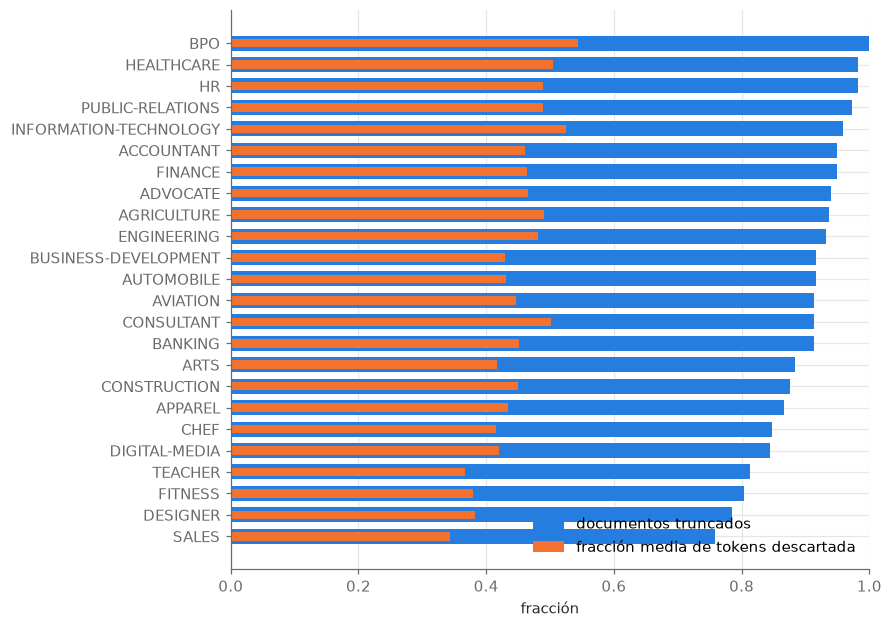

La mediana es de 975 *tokens* WordPiece y el 89.9 % de los currículos supera 510. La tasa de truncamiento va de 75.9 % (SALES) a 100.0 % (BPO); en promedio se descarta el 44.6 % de los *tokens* de un documento.

In [3]:
docs = need("eda/nlp/docs.pkl")
docs = docs[docs.split.isin(["train", "val", "test"])]
tr_ = docs.groupby("Category").agg(n=("n_bert_tokens", "size"), mediana_tokens=("n_bert_tokens", "median"),
                                   truncados_512=("n_bert_tokens", lambda s: (s > 510).mean()),
                                   fraccion_perdida=("n_bert_tokens", lambda s: np.clip(1 - 510 / s.clip(lower=1), 0, 1).mean()))
tr_ = tr_.sort_values("truncados_512")
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(tr_.index, tr_.truncados_512, color=CAT[0], height=0.7, label="documentos truncados")
ax.barh(tr_.index, tr_.fraccion_perdida, color=CAT[1], height=0.4, label="fracción media de tokens descartada")
ax.set(xlabel="fracción", xlim=(0, 1)); ax.legend(loc="lower right")
plt.show()
display(Markdown(f"La mediana es de {docs.n_bert_tokens.median():.0f} *tokens* WordPiece y el {pct((docs.n_bert_tokens > 510).mean())} de los currículos supera 510. "
                 f"La tasa de truncamiento va de {pct(tr_.truncados_512.min())} ({tr_.index[0]}) a {pct(tr_.truncados_512.max())} "
                 f"({tr_.index[-1]}); en promedio se descarta el {pct(np.clip(1 - 510 / docs.n_bert_tokens.clip(lower=1), 0, 1).mean())} "
                 f"de los *tokens* de un documento."))

In [4]:
_fp = tr_.fraccion_perdida.sort_values()
display(Markdown(
    f"La fracción media de *tokens* descartados va de {pct(_fp.iloc[0])} ({_fp.index[0]}) a {pct(_fp.iloc[-1])} ({_fp.index[-1]}). "
    "Las clases con currículos más largos pierden más contenido al truncar, de modo que la ventana fija puede perjudicar más a esas "
    "clases. La sensibilidad a la longitud se mide en el capítulo {doc}`24_nlp_robustez_equidad` con la perturbación «primeras 200 "
    "palabras»."))

La fracción media de *tokens* descartados va de 34.4 % (SALES) a 54.4 % (BPO). Las clases con currículos más largos pierden más contenido al truncar, de modo que la ventana fija puede perjudicar más a esas clases. La sensibilidad a la longitud se mide en el capítulo {doc}`24_nlp_robustez_equidad` con la perturbación «primeras 200 palabras».

## *Embeddings* de palabras

Entrenamos Word2Vec (CBOW y *skip-gram*) {cite:p}`mikolov2013efficient` y FastText *skip-gram* {cite:p}`bojanowski2017fasttext` **solo con los textos de entrenamiento**, con dimensión 100 y 200, ventana 5, frecuencia mínima 2 y 10 épocas. Como vectores preentrenados usamos GloVe de 100 dimensiones (Wikipedia + Gigaword) {cite:p}`pennington2014glove`. La ventana de 5 palabras captura el contexto de una línea de currículo (cargo, empresa, tareas) sin mezclar secciones distintas; las dos dimensiones son las de la rejilla de la BiLSTM.

In [5]:
er = need("nlp/embeddings/embeddings_report.pkl")
cov = pd.DataFrame([dict(vectores=k, vocabulario=v.get("vocab"), cobertura_val=v.get("val_token_coverage"),
                         **{"segundos de entrenamiento": (f"{v['seconds']:.0f}" if v.get("seconds") is not None and np.isfinite(v["seconds"])
                                                         else "— (preentrenado)")})
                    for k, v in er.items() if isinstance(v, dict) and "error" not in v])
cov

,vectores,vocabulario,cobertura_val,segundos de entrenamiento
0,w2v_sg_100,20185,0.972,62
1,w2v_cbow_100,20185,0.972,16
2,fasttext_sg_100,20185,0.972,142
3,w2v_sg_200,20185,0.972,72
4,w2v_cbow_200,20185,0.972,19
5,fasttext_sg_200,20185,0.972,188
6,glove_100,400000,0.991,— (preentrenado)


La cobertura es la fracción de *tokens* de validación que tienen vector propio. FastText construye un vector para cualquier palabra a partir de sus n-gramas de caracteres (3 a 6), así que su cobertura efectiva es total: una palabra mal escrita o un término técnico raro recibe un vector cercano al de sus variantes. Word2Vec y GloVe asignan a esas palabras un vector aleatorio, equivalente a `<UNK>`.

**Evaluación intrínseca.** La tabla muestra los cinco vecinos más cercanos (similitud coseno) de diez palabras del dominio.

In [6]:
from project.nlp_embeddings import PROBES as probes  # noqa: E402
nb = {}
for k in ("w2v_sg_100", "w2v_cbow_100", "fasttext_sg_100", "glove_100"):
    if k in er and "neighbors" in er[k]:
        nb[k] = {p: ", ".join(w for w, _ in (er[k]["neighbors"].get(p) or [])) or "—" for p in probes}
pd.DataFrame(nb)

,w2v_sg_100,w2v_cbow_100,fasttext_sg_100,glove_100
python,"perl, scripting, postgresql, plsql, punjabi","sas, scripting, perl, spss, rational","tsql, plsql, rdb, r3, ajax","monty, php, perl, cleese, flipper"
nurse,"rn, registered, hygienist, inpatient, northbrook","rn, registered, counselor, cna, aide","nursery, nurses, nursing, rn, clinician","doctor, nurses, physician, nursing, dentist"
accounting,"finance, payable, accountant, taxation, bookke...","auditing, ap, budgeting, taxation, administrative","accountemps, counting, discounting, payable, a...","auditing, audit, financial, auditors, practices"
teacher,"substitute, kindergarten, preschool, educator,...","kindergarten, substitute, adjunct, pk, teaching","teaches, teach, teachers, kindergarten, substi...","student, school, teaching, taught, teachers"
sales,"selling, retail, quotas, vigorous, reps","selling, retail, revenue, store, profitability","salesmen, salesman, telesales, salespeople, wh...","retail, revenue, profit, earnings, consumer"
chef,"sous, partie, cook, banquette, expediter","sous, cook, pampered, pastry, hostess","sous, chefs, butcher, cheer, cuisine","chefs, restaurant, restaurateur, gourmet, cuisine"
lawyer,"bail, fd, withdraws, lender, excise","dealings, sphr, jumbo, arden, rho","lawyers, attorneys, subpoena, attorney, landlord","attorney, lawyers, judge, attorneys, counsel"
pilot,"lcs, encore, transitioning, aircrew, dw","mosul, fte, wing, drilling, 1mil","pilots, piloted, battalion, combatant, platoon","pilots, crew, flight, plane, helicopter"
marketing,"advertising, offline, campaigns, sweepstakes, ...","pr, advertising, promotional, communications, ...","marketingpower, remarketing, telemarketing, ma...","advertising, business, merchandising, product,..."
construction,"demolition, project, residential, stair, site","project, phases, interior, residential, engine...","constructions, reconstruction, constructioncon...","building, projects, industrial, built, project"


**Evaluación extrínseca.** Entrenamos la BiLSTM con su mejor configuración y siete variantes de *embeddings*, 3 semillas cada una, y medimos la F1 macro en validación.

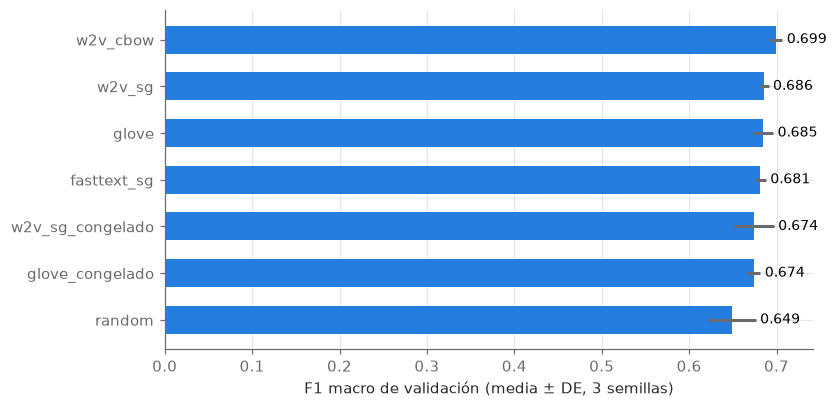

,F1 macro,DE,semillas
variant,,,
w2v_cbow,0.699,0.008,3
w2v_sg,0.686,0.005,3
glove,0.685,0.011,3
fasttext_sg,0.681,0.007,3
w2v_sg_congelado,0.674,0.023,3
glove_congelado,0.674,0.008,3
random,0.649,0.028,3


In [7]:
if exists("nlp/bilstm/emb_ablation/rows.pkl"):
    E = pd.DataFrame(need("nlp/bilstm/emb_ablation/rows.pkl")).drop(columns=["val"])
    g = E.groupby("variant").f1_macro.agg(["mean", "std", "count"]).sort_values("mean", ascending=False)
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    ax.barh(g.index, g["mean"], xerr=g["std"], color=CAT[0], ecolor=MUTED, height=0.6)
    for k, (v, s_) in enumerate(zip(g["mean"], g["std"])):
        ax.text(v + s_ + 0.005, k, f"{v:.3f}", va="center", fontsize=9)
    ax.invert_yaxis(); ax.set(xlabel="F1 macro de validación (media ± DE, 3 semillas)")
    plt.show()
    display(g.rename(columns={"mean": "F1 macro", "std": "DE", "count": "semillas"}))
else:
    display(Markdown("La ablación de *embeddings* no terminó dentro del presupuesto."))

Las variantes congeladas aíslan la calidad de los vectores de partida: si un vector congelado rinde cerca del mismo vector ajustado, la red aprovecha la semántica previa; si rinde mucho menos, el ajuste durante el entrenamiento es lo que aporta. La comparación entre FastText y Word2Vec *skip-gram* mide el efecto de construir vectores para palabras fuera del vocabulario.